In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [58]:
df = pd.read_csv('SeoulBikeData.csv',encoding='latin')
df.shape

(8760, 14)

In [59]:
df

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [61]:
df['Holiday'].nunique()

2

In [64]:

df['Snowfall (cm)'] = df['Snowfall (cm)'].apply(lambda x: 0 if (x==0) else 1)
df['Solar Radiation (MJ/m2)'] = df['Solar Radiation (MJ/m2)'].apply(lambda x: 0 if (x==0) else 1)
df['Rainfall(mm)'] = df['Rainfall(mm)'].apply(lambda x: 0 if (x==0) else 1)
df['Functioning Day'] = df['Functioning Day'].apply(
    lambda x: 0 if str(x) == 'No' else 1
)
df['Functioning Day'].value_counts()
df['Holiday'] = df['Holiday'].apply(lambda x: 0 if str(x) == 'No Holiday' else 1)
df['Holiday'].value_counts()

Holiday
0    8328
1     432
Name: count, dtype: int64

C:\Users\HP\AppData\Local\Temp\ipykernel_3708\3391648829.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[i])
C:\Users\HP\AppData\Local\Temp\ipykernel_3708\3391648829.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[i])
C:\Users\HP\AppData\Local\Temp\ipykernel_3708\3391648829.py:4: U

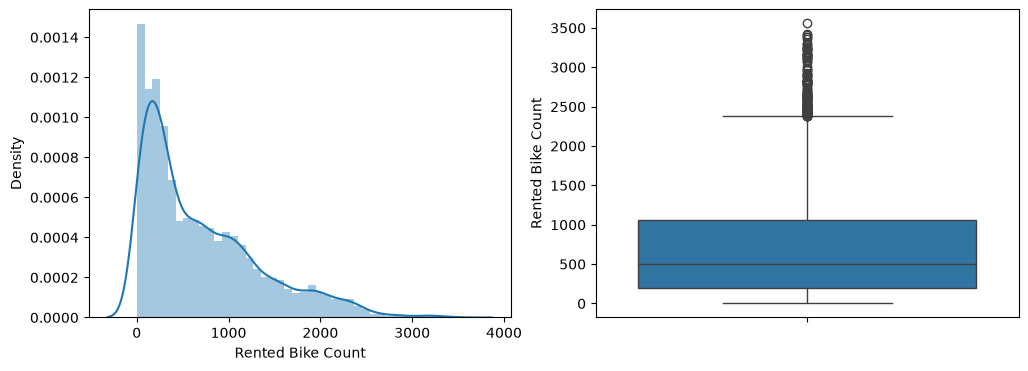

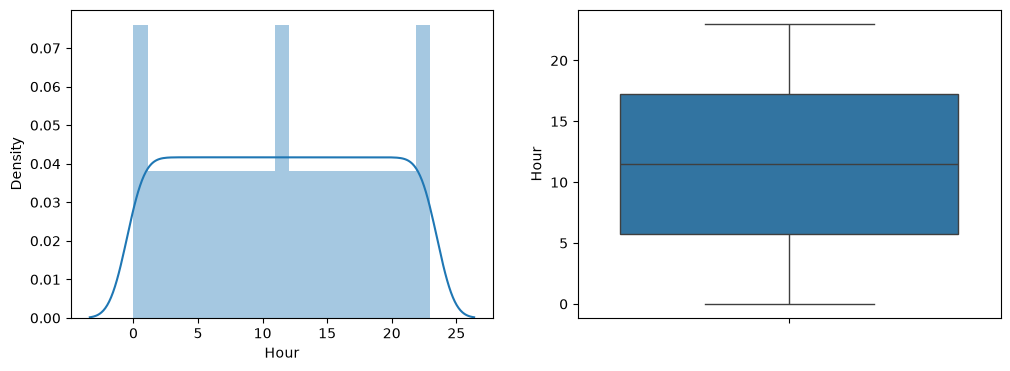

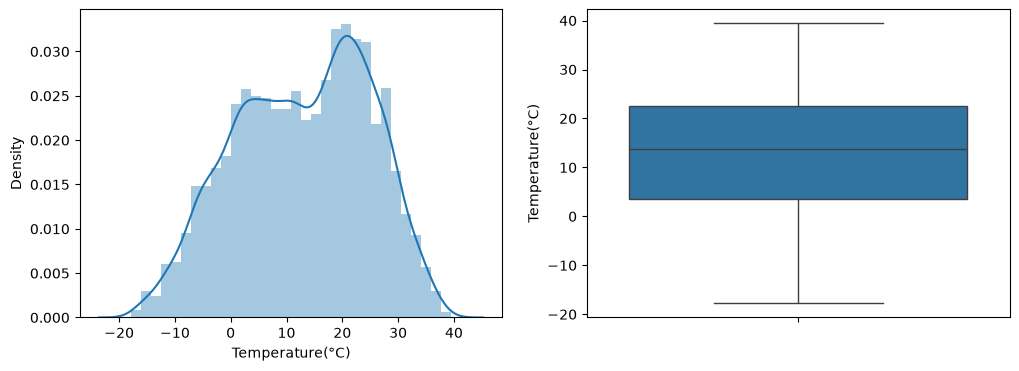

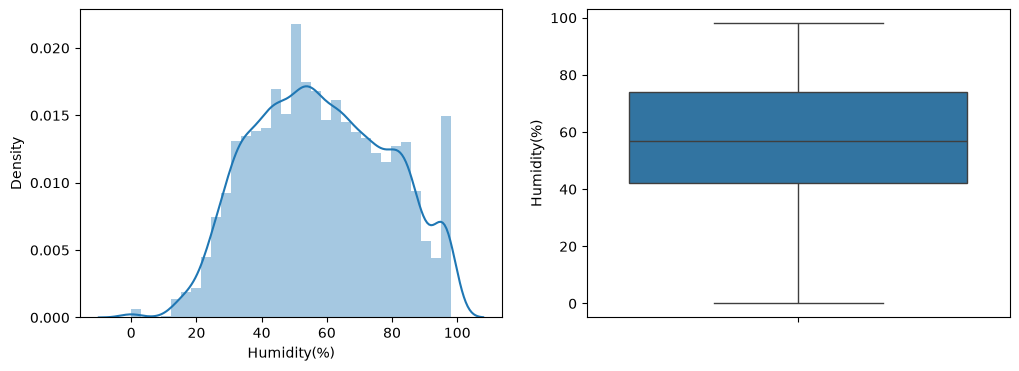

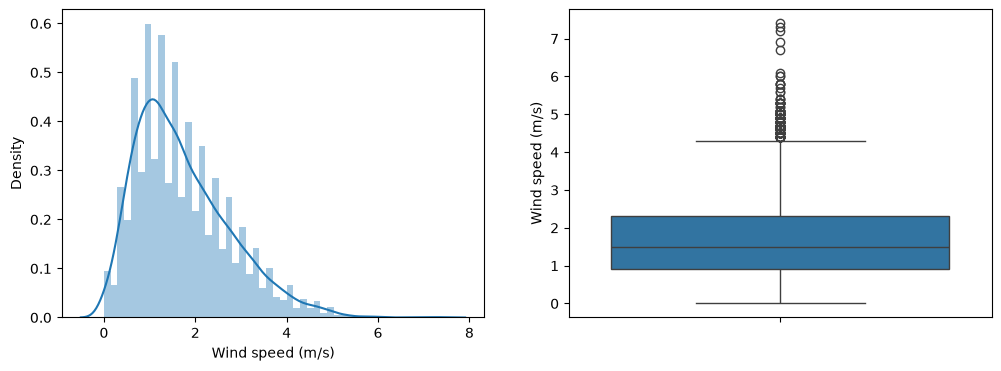

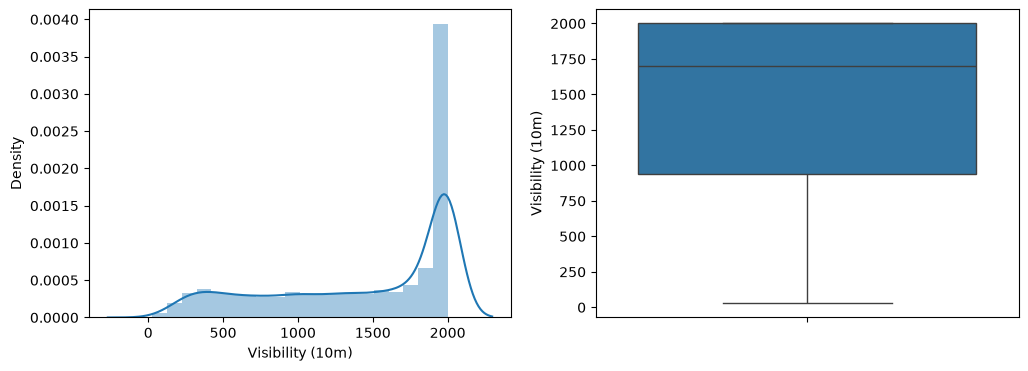

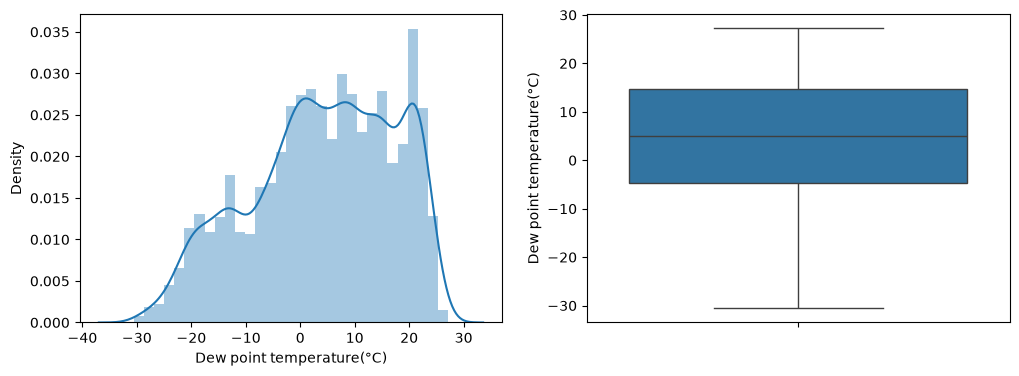

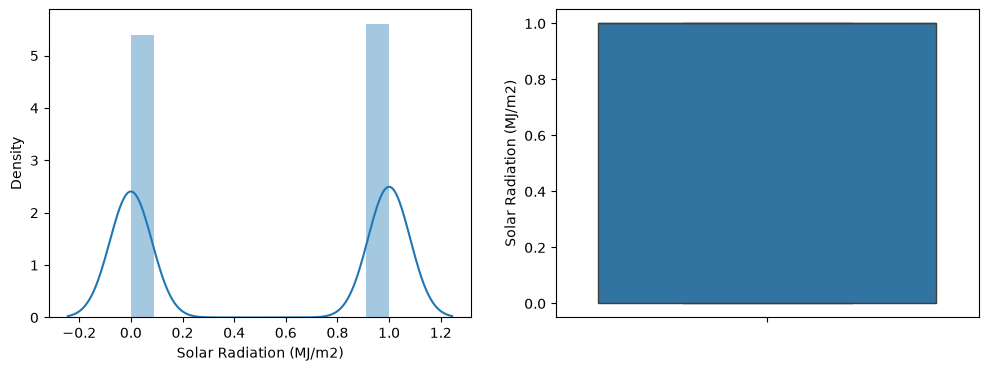

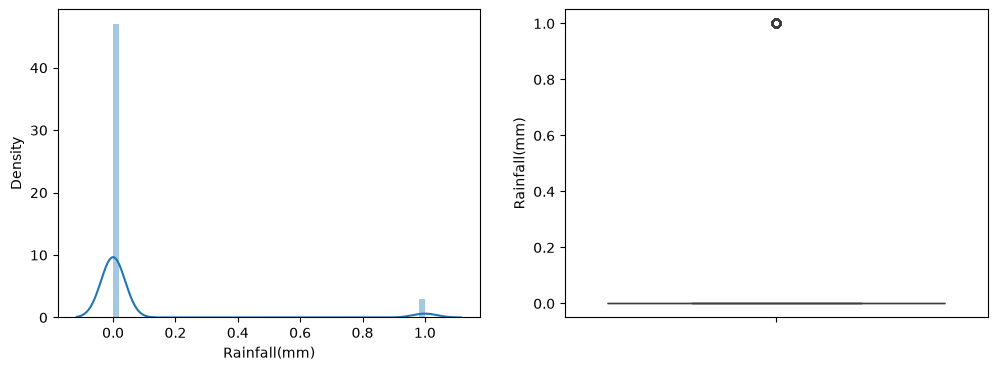

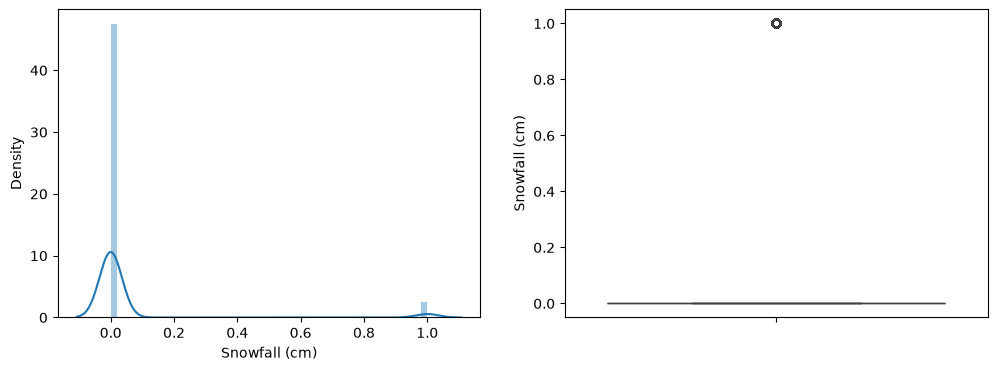

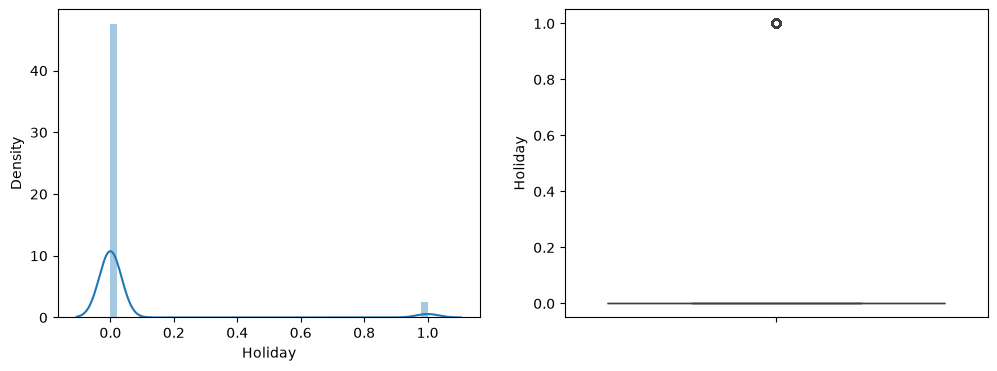

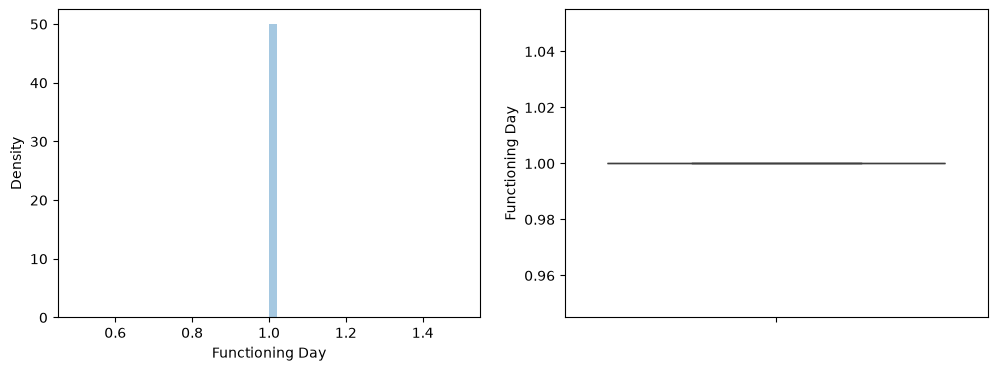

In [69]:
for i in df.select_dtypes(include=['number']).columns:
    plt.figure(figsize=(12, 4))
    plt.subplot(1,2,1)
    sns.distplot(df[i])
    plt.subplot(1,2,2)
    sns.boxplot(df[i])
    
    

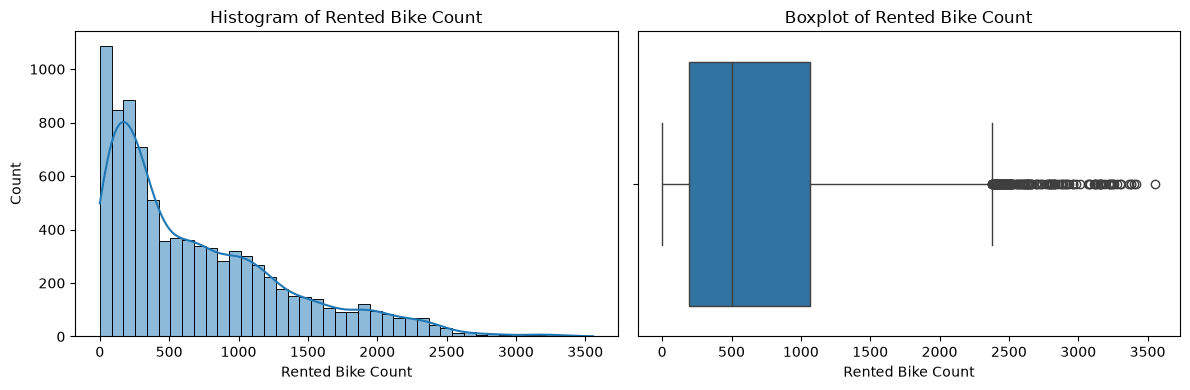

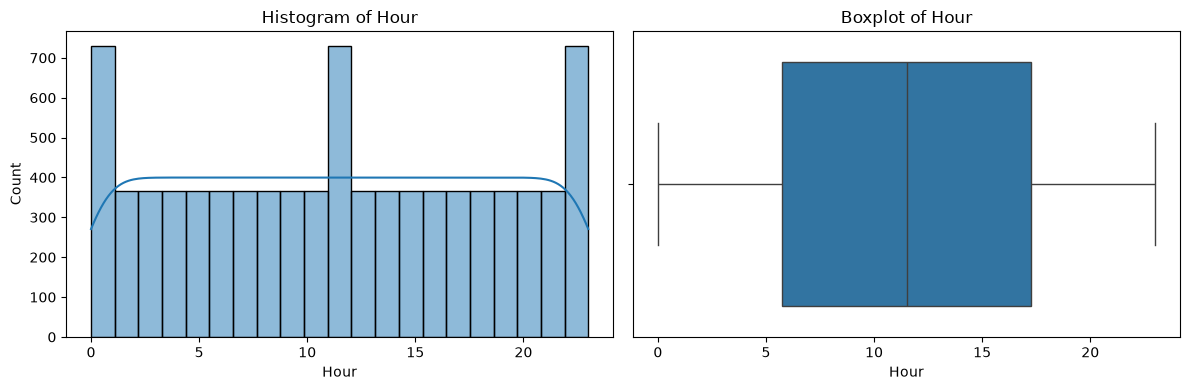

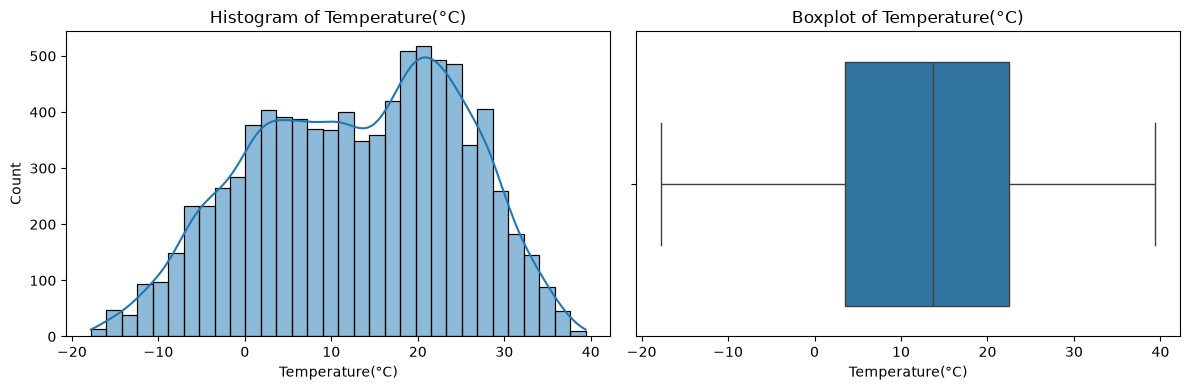

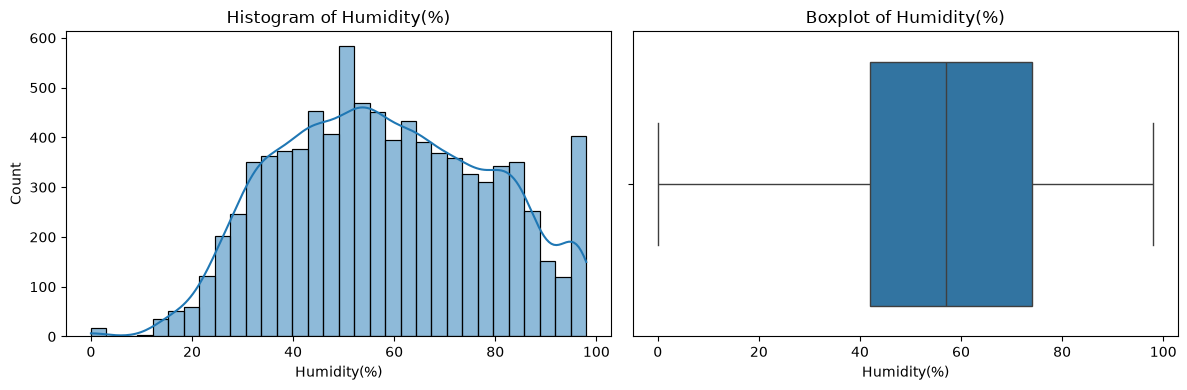

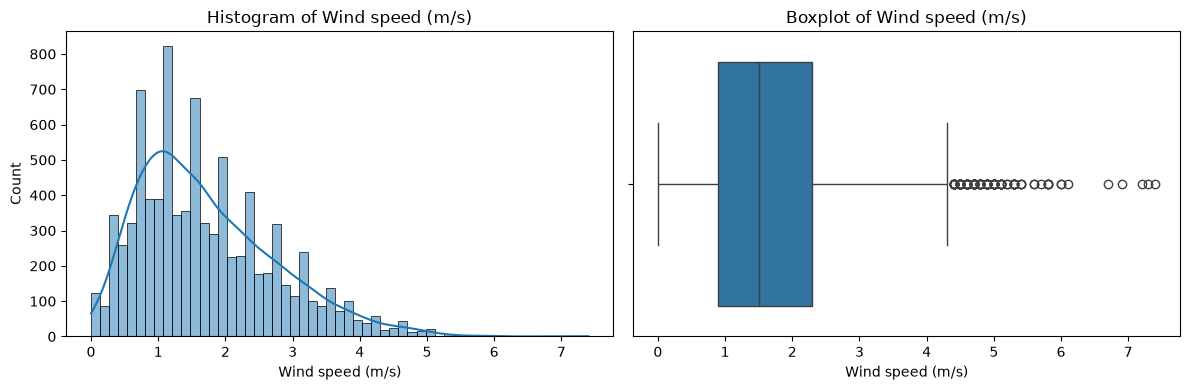

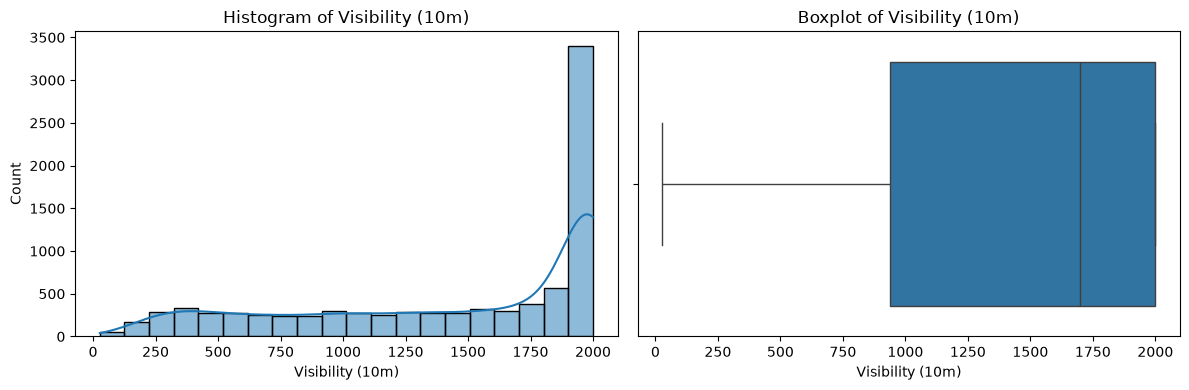

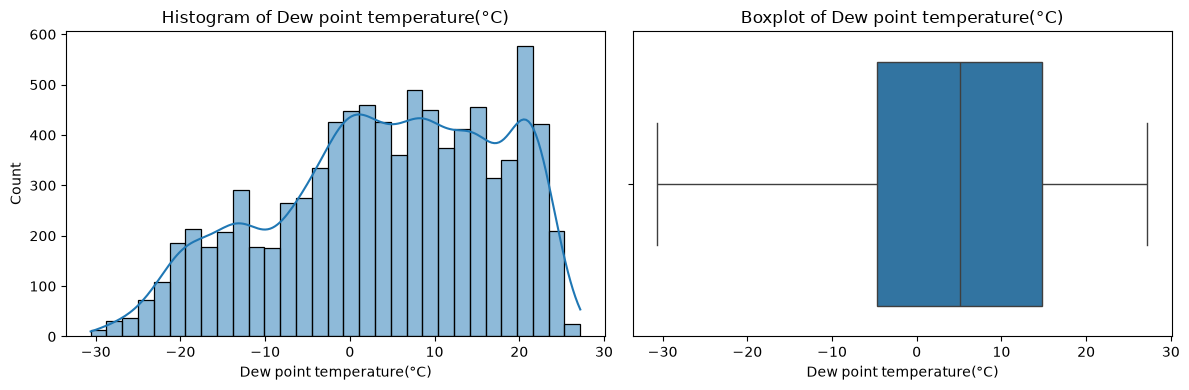

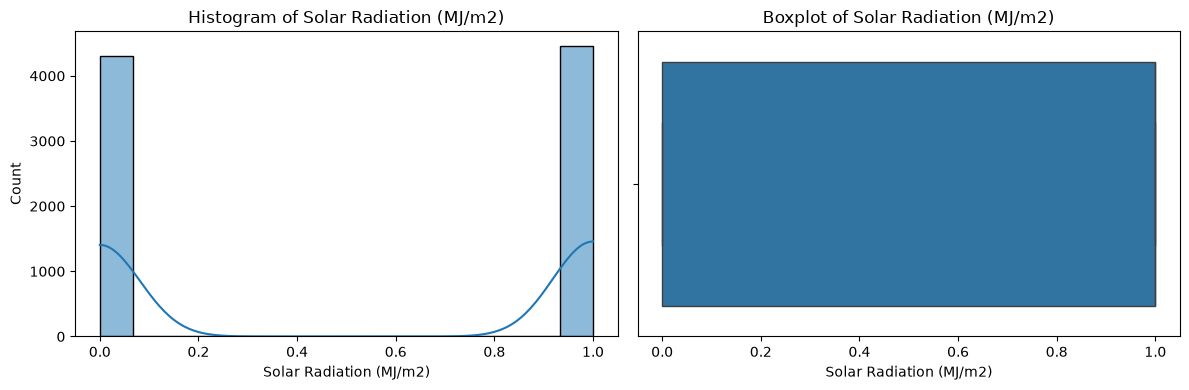

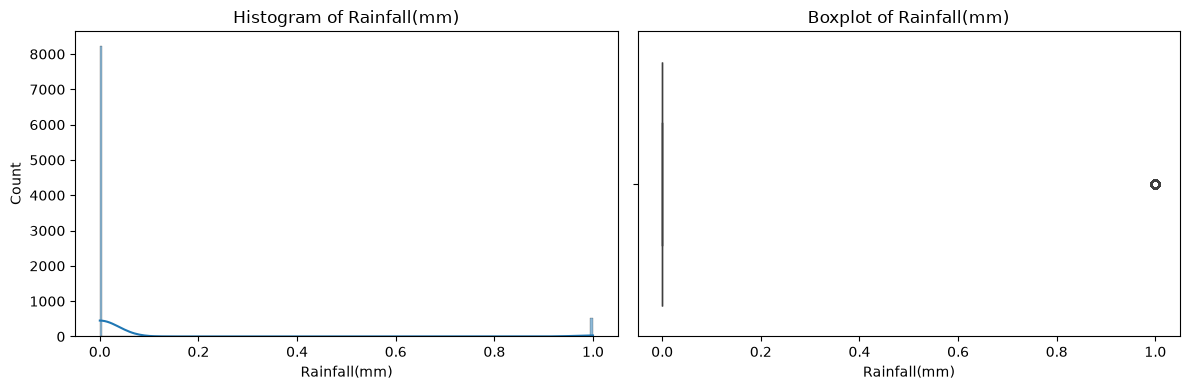

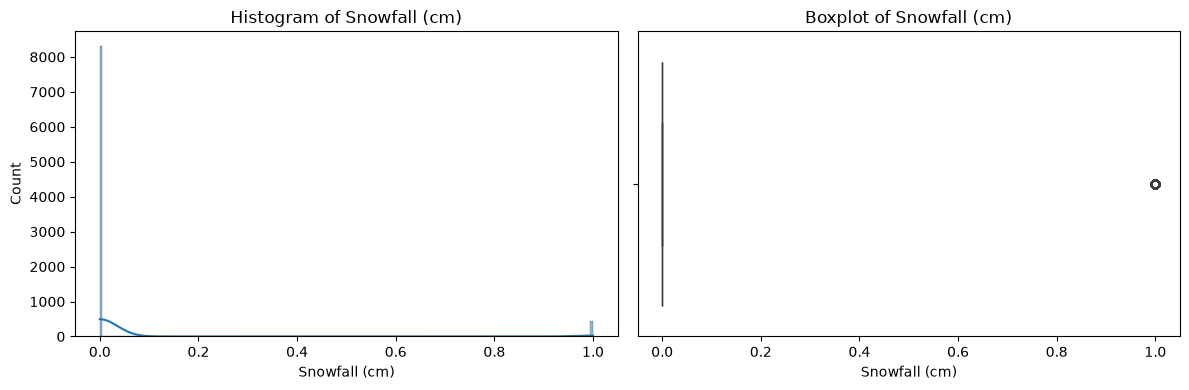

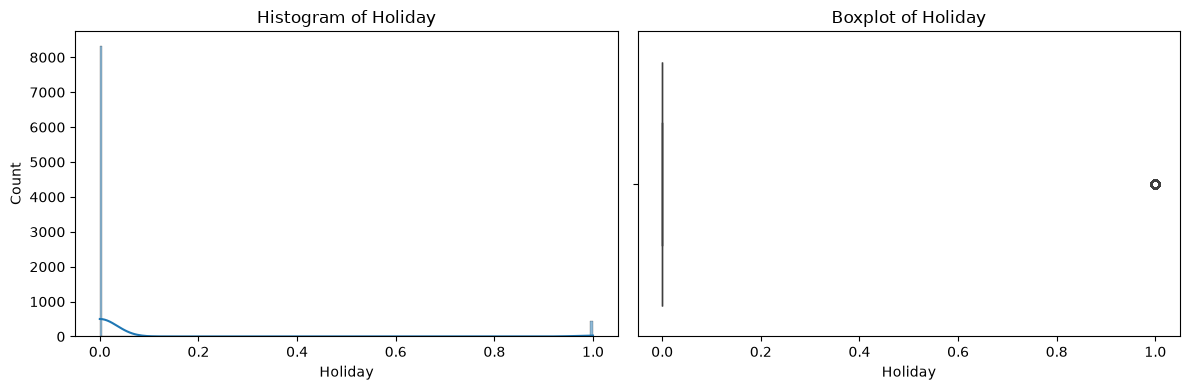

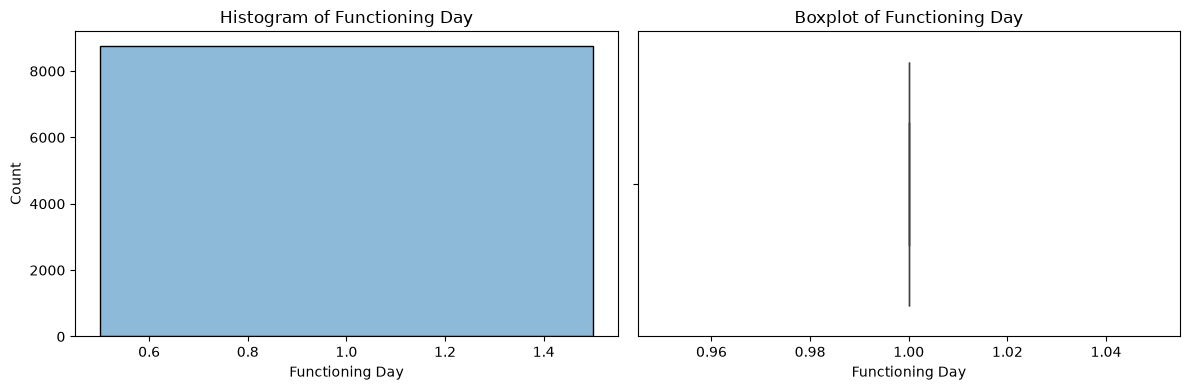

In [68]:
for i in df.select_dtypes(include=['number']).columns:
  plt.figure(figsize=(12, 4))

  plt.subplot(1, 2, 1)
  sns.histplot(df[i], kde=True)  # distplot ki jagah histplot use kar rahe hain
  plt.title(f'Histogram of {i}')

  plt.subplot(1, 2, 2)
  sns.boxplot(x=df[i])
  plt.title(f'Boxplot of {i}')

  plt.tight_layout()
  plt.show()

In [76]:

df.head(5)
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
pi = PowerTransformer(method='yoe-jhonson')
trf = pt.fit_transform(df[['Rented Bike Count']]

_IncompleteInputError: incomplete input (1284787684.py, line 5)

In [77]:
sns.distplot(
pt.fit_transform(df[['Rented Bike Count']]
)

_IncompleteInputError: incomplete input (3490442074.py, line 3)

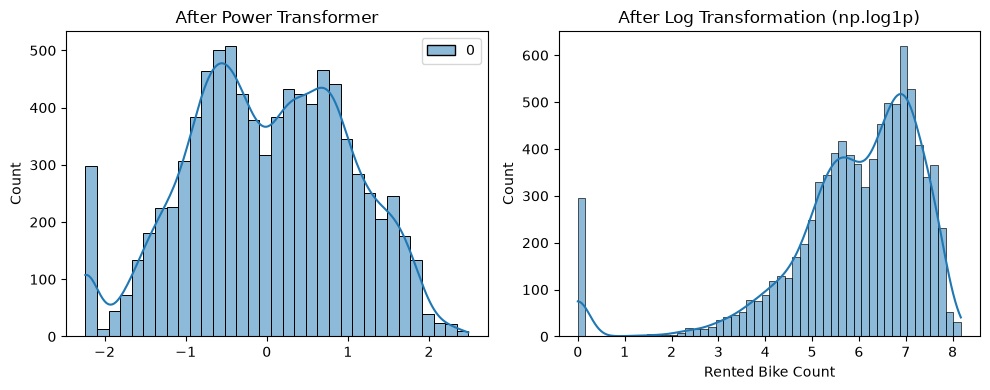

In [78]:
from sklearn.preprocessing import PowerTransformer

# 1. PowerTransformer ka object bana le (method 'yeo-johnson')
pt = PowerTransformer(method='yeo-johnson')

# 2. Bina dataframe ko change kiye, sirf plot karne ke liye:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.histplot(
    pt.fit_transform(df[['Rented Bike Count']]), kde=True
)  # PowerTransformer ke sath
plt.title('After Power Transformer')

plt.subplot(1, 2, 2)
sns.histplot(
    np.log1p(df['Rented Bike Count']), kde=True
)  # Log transformation ke sath
plt.title('After Log Transformation (np.log1p)')

plt.tight_layout()
plt.show()

In [79]:
df

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0,0,0,Winter,0,1
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0,0,0,Winter,0,1
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0,0,0,Winter,0,1
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0,0,0,Winter,0,1
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0,0,0,Winter,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0,0,0,Autumn,0,1
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0,0,0,Autumn,0,1
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0,0,0,Autumn,0,1
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0,0,0,Autumn,0,1


In [81]:
df['Rented Bike Count'] = pt.fit_transform(df[['Rented Bike Count']])

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,-0.530004,0,-5.2,37,2.2,2000,-17.6,0,0,0,Winter,0,1
1,01/12/2017,-0.676497,1,-5.5,38,0.8,2000,-17.6,0,0,0,Winter,0,1
2,01/12/2017,-0.779424,2,-6.0,39,1.0,2000,-17.7,0,0,0,Winter,0,1
3,01/12/2017,-1.047379,3,-6.2,40,0.9,2000,-17.6,0,0,0,Winter,0,1
4,01/12/2017,-1.200315,4,-6.0,36,2.3,2000,-18.6,0,0,0,Winter,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,0.695553,19,4.2,34,2.6,1894,-10.3,0,0,0,Autumn,0,1
8756,30/11/2018,0.403665,20,3.4,37,2.3,2000,-9.9,0,0,0,Autumn,0,1
8757,30/11/2018,0.307082,21,2.6,39,0.3,1968,-9.9,0,0,0,Autumn,0,1
8758,30/11/2018,0.332501,22,2.1,41,1.0,1859,-9.8,0,0,0,Autumn,0,1


<Axes: ylabel='Rented Bike Count'>

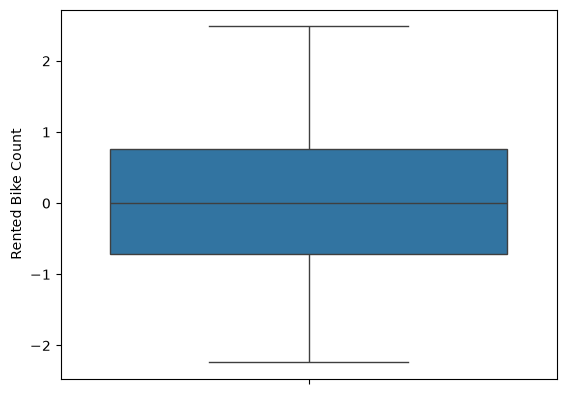

In [83]:
sns.boxplot(df['Rented Bike Count'])

<Axes: xlabel='Wind speed (m/s)', ylabel='Count'>

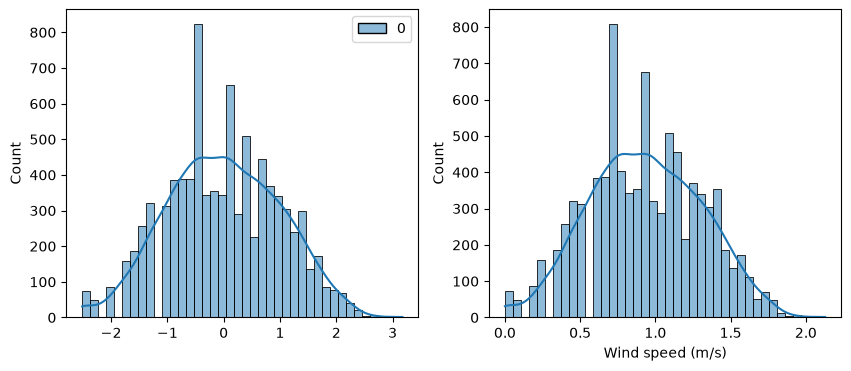

In [85]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.histplot(
    pt.fit_transform(df[['Wind speed (m/s)']]),kde = True
)
plt.subplot(1,2,2)
sns.histplot(
    np.log1p(df['Wind speed (m/s)']),kde=True
)


<Axes: >

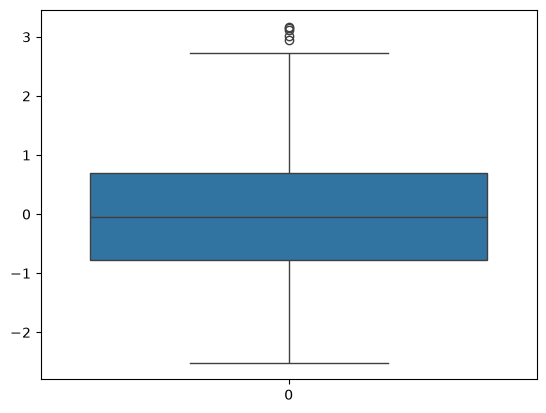

In [89]:
sns.boxplot(pt.fit_transform(df[['Wind speed (m/s)']]))

In [90]:
df['Wind speed (m/s)'] = pt.fit_transform(df[['Wind speed (m/s)']])

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,-0.530004,0,-5.2,37,0.618103,2000,-17.6,0,0,0,Winter,0,1
1,01/12/2017,-0.676497,1,-5.5,38,-0.923651,2000,-17.6,0,0,0,Winter,0,1
2,01/12/2017,-0.779424,2,-6.0,39,-0.640327,2000,-17.7,0,0,0,Winter,0,1
3,01/12/2017,-1.047379,3,-6.2,40,-0.778203,2000,-17.6,0,0,0,Winter,0,1
4,01/12/2017,-1.200315,4,-6.0,36,0.700184,2000,-18.6,0,0,0,Winter,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,0.695553,19,4.2,34,0.932074,1894,-10.3,0,0,0,Autumn,0,1
8756,30/11/2018,0.403665,20,3.4,37,0.700184,2000,-9.9,0,0,0,Autumn,0,1
8757,30/11/2018,0.307082,21,2.6,39,-1.801586,1968,-9.9,0,0,0,Autumn,0,1
8758,30/11/2018,0.332501,22,2.1,41,-0.640327,1859,-9.8,0,0,0,Autumn,0,1


In [95]:
Q1 = df['Wind speed (m/s)'].quantile(0.25)
Q3 = df['Wind speed (m/s)'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5*(IQR)
upper_bound = Q3 + 1.5*(IQR)
def solve(x):
    if(x>upper_bound):
        return upper_bound
    if(x<lower_bound):
        return lower_bound
    return x;
     

In [96]:
df['Wind speed (m/s)'] = df['Wind speed (m/s)'].apply(solve)

<Axes: ylabel='Wind speed (m/s)'>

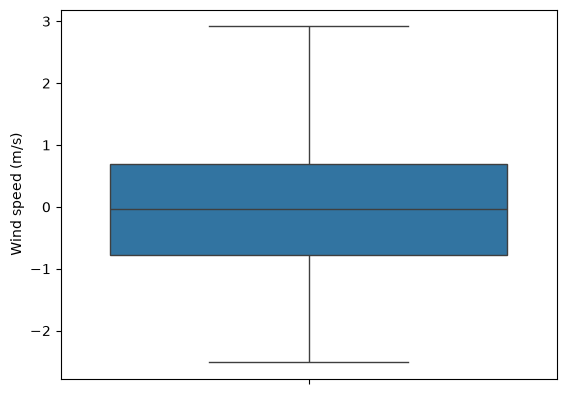

In [97]:
sns.boxplot(df['Wind speed (m/s)'])

In [98]:
df

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,-0.530004,0,-5.2,37,0.618103,2000,-17.6,0,0,0,Winter,0,1
1,01/12/2017,-0.676497,1,-5.5,38,-0.923651,2000,-17.6,0,0,0,Winter,0,1
2,01/12/2017,-0.779424,2,-6.0,39,-0.640327,2000,-17.7,0,0,0,Winter,0,1
3,01/12/2017,-1.047379,3,-6.2,40,-0.778203,2000,-17.6,0,0,0,Winter,0,1
4,01/12/2017,-1.200315,4,-6.0,36,0.700184,2000,-18.6,0,0,0,Winter,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,0.695553,19,4.2,34,0.932074,1894,-10.3,0,0,0,Autumn,0,1
8756,30/11/2018,0.403665,20,3.4,37,0.700184,2000,-9.9,0,0,0,Autumn,0,1
8757,30/11/2018,0.307082,21,2.6,39,-1.801586,1968,-9.9,0,0,0,Autumn,0,1
8758,30/11/2018,0.332501,22,2.1,41,-0.640327,1859,-9.8,0,0,0,Autumn,0,1


In [100]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [102]:
df['Date'].value_counts()


Date
01/12/2017    24
02/12/2017    24
03/12/2017    24
04/12/2017    24
05/12/2017    24
              ..
26/11/2018    24
27/11/2018    24
28/11/2018    24
29/11/2018    24
30/11/2018    24
Name: count, Length: 365, dtype: int64

In [103]:
df

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,-0.530004,0,-5.2,37,0.618103,2000,-17.6,0,0,0,Winter,0,1
1,01/12/2017,-0.676497,1,-5.5,38,-0.923651,2000,-17.6,0,0,0,Winter,0,1
2,01/12/2017,-0.779424,2,-6.0,39,-0.640327,2000,-17.7,0,0,0,Winter,0,1
3,01/12/2017,-1.047379,3,-6.2,40,-0.778203,2000,-17.6,0,0,0,Winter,0,1
4,01/12/2017,-1.200315,4,-6.0,36,0.700184,2000,-18.6,0,0,0,Winter,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,0.695553,19,4.2,34,0.932074,1894,-10.3,0,0,0,Autumn,0,1
8756,30/11/2018,0.403665,20,3.4,37,0.700184,2000,-9.9,0,0,0,Autumn,0,1
8757,30/11/2018,0.307082,21,2.6,39,-1.801586,1968,-9.9,0,0,0,Autumn,0,1
8758,30/11/2018,0.332501,22,2.1,41,-0.640327,1859,-9.8,0,0,0,Autumn,0,1


In [109]:
X = df.iloc[:,2:]
Y = df.iloc[:,1]
from sklearn.linear_model import LinearRegression


In [113]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=2)

In [114]:
trf = ColumnTransformer(transformers=[
    ('OHE',OneHotEncoder(handle_unknown='ignore'),['Seasons']),
    
],remainder='passthrough')
pipe = Pipeline([
    ('trf',trf),
    ('model',LinearRegression())
])

In [115]:
pipe.fit(X_train,Y_train)
u = pipe.predict(X_test)

In [116]:
from sklearn.metrics import r2_score

In [118]:
r2_score(Y_test,u)

0.5157100269579394

In [120]:
df['Date'] = pd.to_datetime(df['Date'],format='%d/%m/%Y') 

In [122]:
df['Day'] = df['Date'].dt.day
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['DayOfWeek'] = df['Date'].dt.dayofweek  # 0 = Monday, 6 = Sunday
df['Is_Weekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

In [125]:
df

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Day,Month,Year,DayOfWeek,Is_Weekend
0,2017-12-01,-0.530004,0,-5.2,37,0.618103,2000,-17.6,0,0,0,Winter,0,1,1,12,2017,4,0
1,2017-12-01,-0.676497,1,-5.5,38,-0.923651,2000,-17.6,0,0,0,Winter,0,1,1,12,2017,4,0
2,2017-12-01,-0.779424,2,-6.0,39,-0.640327,2000,-17.7,0,0,0,Winter,0,1,1,12,2017,4,0
3,2017-12-01,-1.047379,3,-6.2,40,-0.778203,2000,-17.6,0,0,0,Winter,0,1,1,12,2017,4,0
4,2017-12-01,-1.200315,4,-6.0,36,0.700184,2000,-18.6,0,0,0,Winter,0,1,1,12,2017,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2018-11-30,0.695553,19,4.2,34,0.932074,1894,-10.3,0,0,0,Autumn,0,1,30,11,2018,4,0
8756,2018-11-30,0.403665,20,3.4,37,0.700184,2000,-9.9,0,0,0,Autumn,0,1,30,11,2018,4,0
8757,2018-11-30,0.307082,21,2.6,39,-1.801586,1968,-9.9,0,0,0,Autumn,0,1,30,11,2018,4,0
8758,2018-11-30,0.332501,22,2.1,41,-0.640327,1859,-9.8,0,0,0,Autumn,0,1,30,11,2018,4,0


In [126]:
df = df.drop(columns=['Date'])
            

In [127]:
df

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Day,Month,Year,DayOfWeek,Is_Weekend
0,-0.530004,0,-5.2,37,0.618103,2000,-17.6,0,0,0,Winter,0,1,1,12,2017,4,0
1,-0.676497,1,-5.5,38,-0.923651,2000,-17.6,0,0,0,Winter,0,1,1,12,2017,4,0
2,-0.779424,2,-6.0,39,-0.640327,2000,-17.7,0,0,0,Winter,0,1,1,12,2017,4,0
3,-1.047379,3,-6.2,40,-0.778203,2000,-17.6,0,0,0,Winter,0,1,1,12,2017,4,0
4,-1.200315,4,-6.0,36,0.700184,2000,-18.6,0,0,0,Winter,0,1,1,12,2017,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,0.695553,19,4.2,34,0.932074,1894,-10.3,0,0,0,Autumn,0,1,30,11,2018,4,0
8756,0.403665,20,3.4,37,0.700184,2000,-9.9,0,0,0,Autumn,0,1,30,11,2018,4,0
8757,0.307082,21,2.6,39,-1.801586,1968,-9.9,0,0,0,Autumn,0,1,30,11,2018,4,0
8758,0.332501,22,2.1,41,-0.640327,1859,-9.8,0,0,0,Autumn,0,1,30,11,2018,4,0


In [132]:
# Agar 2017 ko 0 aur 2018 ko 1 banana hai:
df['Year'] = df['Year'].apply(lambda x: 0 if x == 2017 else 1)

# Check karne ke liye
print(df['Year'].value_counts())

Year
1    8016
0     744
Name: count, dtype: int64


In [133]:
df

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Day,Month,Year,DayOfWeek,Is_Weekend
0,-0.530004,0,-5.2,37,0.618103,2000,-17.6,0,0,0,Winter,0,1,1,12,0,4,0
1,-0.676497,1,-5.5,38,-0.923651,2000,-17.6,0,0,0,Winter,0,1,1,12,0,4,0
2,-0.779424,2,-6.0,39,-0.640327,2000,-17.7,0,0,0,Winter,0,1,1,12,0,4,0
3,-1.047379,3,-6.2,40,-0.778203,2000,-17.6,0,0,0,Winter,0,1,1,12,0,4,0
4,-1.200315,4,-6.0,36,0.700184,2000,-18.6,0,0,0,Winter,0,1,1,12,0,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,0.695553,19,4.2,34,0.932074,1894,-10.3,0,0,0,Autumn,0,1,30,11,1,4,0
8756,0.403665,20,3.4,37,0.700184,2000,-9.9,0,0,0,Autumn,0,1,30,11,1,4,0
8757,0.307082,21,2.6,39,-1.801586,1968,-9.9,0,0,0,Autumn,0,1,30,11,1,4,0
8758,0.332501,22,2.1,41,-0.640327,1859,-9.8,0,0,0,Autumn,0,1,30,11,1,4,0


In [134]:
X_train,X_test,Y_train,Y_test = train_test_split(df.drop(columns=['Rented Bike Count']),df['Rented Bike Count'],test_size=
                                                0.2,random_state=2)

In [136]:
trf = ColumnTransformer(transformers=[
    ('OHE',OneHotEncoder(handle_unknown='ignore'),['Seasons']),
    
],remainder='passthrough')
pipe = Pipeline([
    ('trf',trf),
    ('model',LinearRegression())
])
pipe.fit(X_train,Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('trf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Hour','Temperature(°C)','Humidity(%)',...,'Year','DayOfWeek', 'Is_Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OHE', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated w

In [142]:
u = pipe.predict(X_test)

In [138]:
r2_score(Y_test,u)

0.5190065528264957

In [139]:
df

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Day,Month,Year,DayOfWeek,Is_Weekend
0,-0.530004,0,-5.2,37,0.618103,2000,-17.6,0,0,0,Winter,0,1,1,12,0,4,0
1,-0.676497,1,-5.5,38,-0.923651,2000,-17.6,0,0,0,Winter,0,1,1,12,0,4,0
2,-0.779424,2,-6.0,39,-0.640327,2000,-17.7,0,0,0,Winter,0,1,1,12,0,4,0
3,-1.047379,3,-6.2,40,-0.778203,2000,-17.6,0,0,0,Winter,0,1,1,12,0,4,0
4,-1.200315,4,-6.0,36,0.700184,2000,-18.6,0,0,0,Winter,0,1,1,12,0,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,0.695553,19,4.2,34,0.932074,1894,-10.3,0,0,0,Autumn,0,1,30,11,1,4,0
8756,0.403665,20,3.4,37,0.700184,2000,-9.9,0,0,0,Autumn,0,1,30,11,1,4,0
8757,0.307082,21,2.6,39,-1.801586,1968,-9.9,0,0,0,Autumn,0,1,30,11,1,4,0
8758,0.332501,22,2.1,41,-0.640327,1859,-9.8,0,0,0,Autumn,0,1,30,11,1,4,0
